# Confirmatory data analysis

Survey of veterinary students who study (or studied) in Hungary. This notebook compares **neurodivergent (ND) and not neurodivergent students** and follows up on the main patterns found in `eba.ipynb`:

- **ND vs not ND**: how the two groups differ in depression, anxiety and wellbeing.
- **Overwhelm vs symptoms**: whether academic overwhelm goes with more symptoms in both groups.
- **Worsened mental state**: how many students say their mental state got worse since starting university.
- **Lifestyle vs symptoms**: whether sleep, meals, exercise and free time go with fewer symptoms.

Every chart has the same notes as in the EDA: **Columns used**, **What the graph shows**, **Conclusions** and, where needed, **Limits**. Column numbers refer to `datasets/codebook.csv`. The limitations listed in the EDA's *About the sample* slide apply here too, in particular the small groups (about 40 students each).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("./datasets/forms-answers-cleaned-hungary.csv")
assert not df.duplicated(subset=df.columns.drop("0")).any(), "duplicate submissions"
assert (df["7"] == "Hungary").all(), "the sample should only contain students from Hungary"

## Neurodivergent vs not neurodivergent students

**Columns used**
- Column 9, *"How do you identify yourself?"* (more than one answer allowed):
  - **Neurodivergent**: ticked *Diagnosed neurodivergent* and/or *Self identified neurodivergent*, even if they also ticked another option.
  - **Not neurodivergent**: ticked only *Neurotypical* and/or *I haven't thought much of it*.
- The same grouping as in the EDA, used in every comparison in this notebook.

**What the graph shows**
- **Left:** the number and % of students in each group.
- **Right:** what the students in each group ticked in column 9. A student who ticked two options is counted once, under the combination they ticked.

**Conclusions**
- **42 students (53%) identify as neurodivergent and 37 (47%) do not.** The groups are close in size, so comparing them is reasonably balanced.
- **3 students ticked a neurodivergent option together with *Neurotypical* or *I haven't thought much of it*.** They are counted as neurodivergent, because they ticked a neurodivergent option.
- About 40 students per group means one student is about 2.5% of their group: only fairly large differences between the groups can be told apart from chance.

**Limits**
- The *Not neurodivergent* group includes students who answered *I haven't thought much of it*, and some of them may be neurodivergent without knowing it. This would make the two groups look more alike than they are.

,students,%
nd_group,,
Neurodivergent,42,53.0
Not neurodivergent,37,47.0


nd_group,Neurodivergent,Not neurodivergent
9,,
Diagnosed ND,21,0
Diagnosed ND + Self-identified ND,4,0
Haven't thought much of it,0,15
Neurotypical,0,20
Neurotypical + Haven't thought much of it,0,2
Self-identified ND,14,0
Self-identified ND + Haven't thought much of it,2,0
Self-identified ND + Neurotypical,1,0


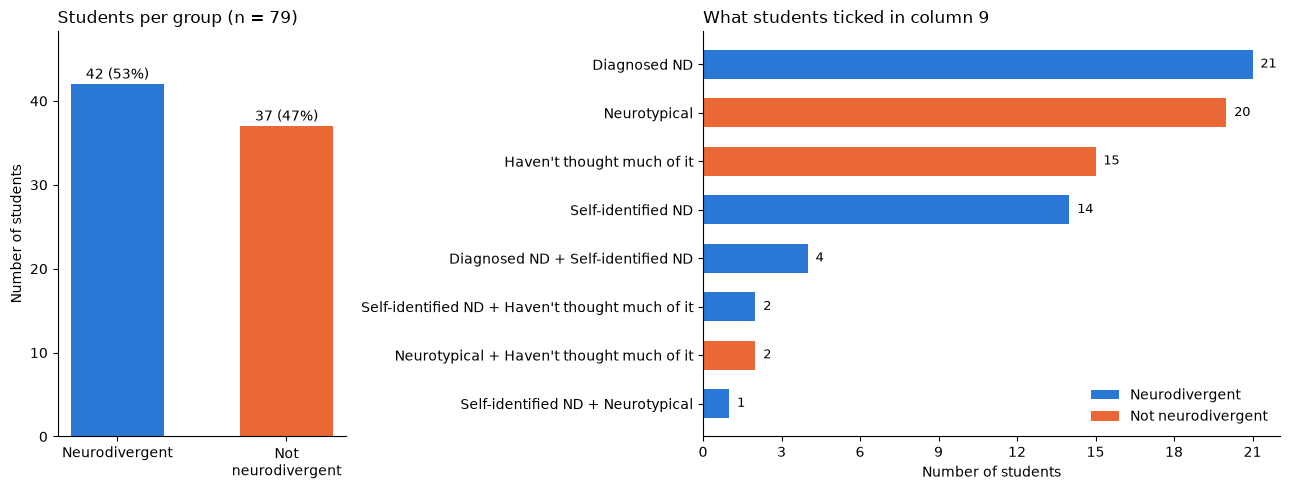

In [3]:
ND_COLOR = "#2a78d6"
NON_ND_COLOR = "#eb6834"
GROUP_ORDER = ["Neurodivergent", "Not neurodivergent"]
GROUP_COLORS = [ND_COLOR, NON_ND_COLOR]

# Column 9 is multi-select: anyone who ticked a "neurodivergent" option (diagnosed or self-identified) counts as ND
df["neurodivergent"] = df["9"].str.contains("neurodivergent", case=False, na=False)
df["nd_group"] = df["neurodivergent"].map({True: "Neurodivergent", False: "Not neurodivergent"})

nd_counts = df["nd_group"].value_counts().reindex(GROUP_ORDER)
# What each student ticked in column 9, with short option names (joined with " + " when they ticked more than one)
OPTION_NAMES = {
    "Diagnosed neurodivergent (you have received a medical diagnosis)": "Diagnosed ND",
    "Self identified neurodivergent (no formal diagnosis)": "Self-identified ND",
    "Neurotypical": "Neurotypical",
    "I haven't thought much of it.": "Haven't thought much of it",
}
answers_9 = df["9"].str.split(";").map(lambda options: " + ".join(OPTION_NAMES[o] for o in options))
breakdown = pd.crosstab(answers_9, df["nd_group"]).reindex(columns=GROUP_ORDER)
display(nd_counts.to_frame("students").assign(**{"%": (nd_counts / nd_counts.sum() * 100).round(0)}))
display(breakdown)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1, 2]})

# Left: students per group
bars = ax1.bar(["Neurodivergent", "Not\nneurodivergent"], nd_counts.values, color=GROUP_COLORS, width=0.55)
for bar, n in zip(bars, nd_counts.values):
    ax1.annotate(f"{n} ({n / nd_counts.sum():.0%})", (bar.get_x() + bar.get_width() / 2, n),
                 xytext=(0, 4), textcoords="offset points", ha="center")
ax1.set_ylabel("Number of students")
ax1.set_ylim(0, nd_counts.max() * 1.15)
ax1.set_title(f"Students per group (n = {nd_counts.sum()})", loc="left")
ax1.spines[["top", "right"]].set_visible(False)

# Right: column 9 answers in each group, most common first
rows = breakdown.sum(axis=1).sort_values().index
y = range(len(rows))
for group, color in zip(GROUP_ORDER, GROUP_COLORS):
    values = breakdown.loc[rows, group]
    shown = values > 0
    ax2.barh([yi for yi, s in zip(y, shown) if s], values[shown], color=color, height=0.6, label=group)
    for yi, v in zip(y, values):
        if v > 0:
            ax2.text(v + 0.3, yi, str(v), va="center", fontsize=9)
ax2.set_yticks(list(y), rows)
ax2.set_xlabel("Number of students")
ax2.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax2.set_title("What students ticked in column 9", loc="left")
ax2.legend(frameon=False, loc="lower right")
ax2.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

## How common are depression and anxiety: ND vs not ND

### Depression and anxiety screening (PHQ-9 and GAD-7)

**Columns used**
- **Depression: PHQ-9**, 9 items (columns 70–78), each scored 0–3, so totals run from 0 to 27.
- **Anxiety: GAD-7**, 7 items (columns 79–85), each scored 0–3, so totals run from 0 to 21.
- Both ask about the **last 2 weeks**.
- Missing answers are handled as in the EDA: the 5 students who skipped one PHQ-9 item (2 ND, 3 not ND) get the average of their other 8 items in its place (prorating). The 2 students who skipped the whole PHQ-9 are both not ND and are left out, so the depression graphs have 42 ND and 35 not ND students. The GAD-7 is complete (42 and 37).
- Neurodivergent vs not neurodivergent (column 9, as in the first chart).

**What the graph shows**
- **Top:** the **% of each group** at each total score: blue = neurodivergent, orange = not neurodivergent. Percentages are used because the groups are not the same size. The **shaded area** covers scores of 10 or more, the standard cut-off for at least *moderate* symptoms, and the number and % of each group in it is written at the top left.
- With about 40 students per group, one student is 2–3% of the group, so the lines are jagged. The bands below are easier to compare.
- **Bottom:** the same scores in their standard severity bands, as 100% stacked bars (darker = more severe).
- The tables above the plot give the number and % of students in each band, and the average, median and % scoring 10 or more in each group.

**Conclusions**
- **Depression and anxiety symptoms are very common in both groups.** 79% of ND students (33 of 42) and 74% of not ND students (26 of 35) score 10 or more on the PHQ-9, and 74% (31 of 42) and 73% (27 of 37) on the GAD-7.
- **Anxiety is the same in both groups**: average 12.2 vs 12.3, and 38% of each group has *severe* anxiety symptoms (15 or more).
- **Neurodivergent students more often have severe depression symptoms.** Their averages are close (15.4 vs 13.8), but 55% of ND students (23 of 42) score 15 or more (*moderately severe* or *severe*), against 37% of not ND students (13 of 35). The difference is in the most severe bands, not in how many students reach the moderate cut-off.

**Limits**
- The severe-depression gap is 18 points, which with about 40 students per group is roughly 7 students. It is large enough to be worth noting but could still be chance: it is a **hint** to confirm in a larger sample.
- The PHQ-9 and GAD-7 are screening tools, not a diagnosis. Several items (trouble concentrating, restlessness, sleep) overlap with ADHD and other neurodivergent traits, which could push ND students' scores up without more depression or anxiety.
- The *Not neurodivergent* group includes students who *haven't thought much of it*, some of whom may be neurodivergent; this would make the groups look more alike.

PHQ-9 items missing per student,0,1,9
Neurodivergent,40,2,0
Not neurodivergent,32,3,2


n  average  median  score ≥ 10  \
score              group                                                 
Depression (PHQ-9) Neurodivergent      42     15.4    16.0          33   
                   Not neurodivergent  35     13.8    13.0          26   
Anxiety (GAD-7)    Neurodivergent      42     12.2    13.0          31   
                   Not neurodivergent  37     12.3    14.0          27   

                                       % ≥ 10  score ≥ 15  % ≥ 15  
score              group                                           
Depression (PHQ-9) Neurodivergent        78.6          23    54.8  
                   Not neurodivergent    74.3          13    37.1  
Anxiety (GAD-7)    Neurodivergent        73.8          16    38.1  
                   Not neurodivergent    73.0          14    37.8

students                        % of group  \
nd_group                  Neurodivergent Not neurodivergent Neurodivergent   
Depression (PHQ-9)                                                           
Minimal (0-4)                          2                  0            5.0   
Mild (5-9)                             7                  9           17.0   
Moderate (10-14)                      10                 13           24.0   
Moderately severe (15-19)             11                  6           26.0   
Severe (20-27)                        12                  7           29.0   

                                              
nd_group                  Not neurodivergent  
Depression (PHQ-9)                            
Minimal (0-4)                            0.0  
Mild (5-9)                              26.0  
Moderate (10-14)                        37.0  
Moderately severe (15-19)               17.0  
Severe (20-27)                          20.0

students                        % of group  \
nd_group         Neurodivergent Not neurodivergent Neurodivergent   
Anxiety (GAD-7)                                                     
Minimal (0-4)                 5                  4           12.0   
Mild (5-9)                    6                  6           14.0   
Moderate (10-14)             15                 13           36.0   
Severe (15-21)               16                 14           38.0   

                                     
nd_group         Not neurodivergent  
Anxiety (GAD-7)                      
Minimal (0-4)                  11.0  
Mild (5-9)                     16.0  
Moderate (10-14)               35.0  
Severe (15-21)                 38.0

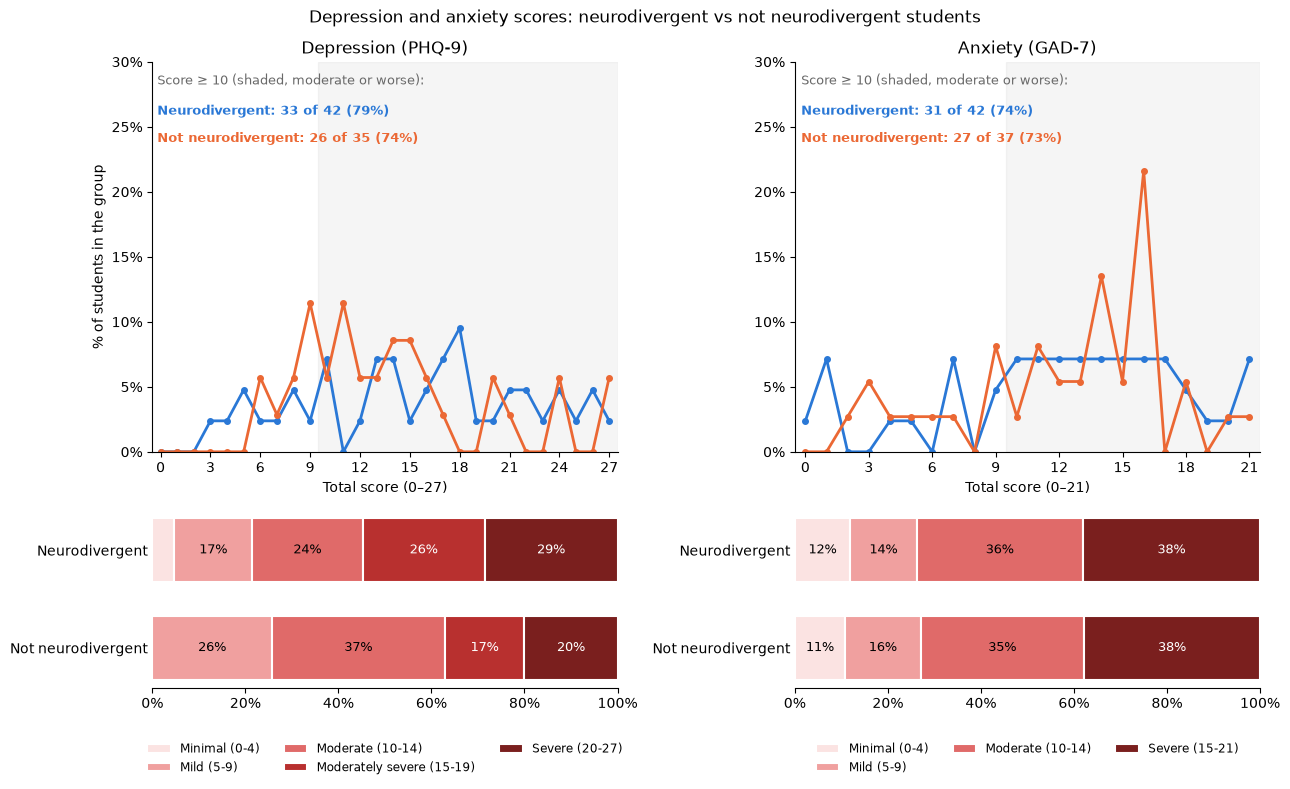

In [4]:
PHQ9_COLS = [str(c) for c in range(70, 79)]  # depression items, each 0-3
GAD7_COLS = [str(c) for c in range(79, 86)]  # anxiety items, each 0-3
values = df[PHQ9_COLS + GAD7_COLS].stack().dropna()
assert values.between(0, 3).all() and (values % 1 == 0).all(), "PHQ-9 / GAD-7 answers outside 0-3"

def screening_total(items):
    # Prorate when at most one item is missing; otherwise leave the score empty
    answered = items.notna().sum(axis=1)
    total = items.mean(axis=1) * items.shape[1]
    return total.where(answered >= items.shape[1] - 1).round()

df["phq9_total"] = screening_total(df[PHQ9_COLS])
df["gad7_total"] = screening_total(df[GAD7_COLS])
display(df[PHQ9_COLS].isna().sum(axis=1).groupby(df["nd_group"]).value_counts().unstack(fill_value=0)
        .rename_axis(index=None, columns="PHQ-9 items missing per student"))

PHQ9_BANDS = ([-1, 4, 9, 14, 19, 27], ["Minimal (0-4)", "Mild (5-9)", "Moderate (10-14)", "Moderately severe (15-19)", "Severe (20-27)"])
GAD7_BANDS = ([-1, 4, 9, 14, 21], ["Minimal (0-4)", "Mild (5-9)", "Moderate (10-14)", "Severe (15-21)"])
screenings = [
    ("Depression (PHQ-9)", "phq9_total", 27, PHQ9_BANDS),
    ("Anxiety (GAD-7)", "gad7_total", 21, GAD7_BANDS),
]
BAND_COLORS = ["#fbe3e2", "#f0a09f", "#e06a69", "#b8302f", "#7a1f1e"]  # light to dark red: more severe

# Summary per group: n, average, median, % at least moderate (10+) and % (moderately) severe (15+)
rows = []
for name, col, _, _ in screenings:
    for group in GROUP_ORDER:
        scores = df.loc[df["nd_group"] == group, col].dropna()
        rows.append({"score": name, "group": group, "n": len(scores), "average": scores.mean(),
                     "median": scores.median(), "score ≥ 10": (scores >= 10).sum(),
                     "% ≥ 10": (scores >= 10).mean() * 100, "score ≥ 15": (scores >= 15).sum(),
                     "% ≥ 15": (scores >= 15).mean() * 100})
display(pd.DataFrame(rows).set_index(["score", "group"]).round(1))

# Severity bands: number and % of each group
band_shares = {}
for name, col, _, (bins, labels) in screenings:
    answered = df.dropna(subset=[col])
    bands = pd.crosstab(pd.cut(answered[col], bins=bins, labels=labels), answered["nd_group"]).reindex(columns=GROUP_ORDER)
    band_shares[col] = bands / bands.sum()
    display(pd.concat({"students": bands, "% of group": (band_shares[col] * 100).round(0)}, axis=1)
            .rename_axis(name))

fig, axes = plt.subplots(2, 2, figsize=(13, 8), gridspec_kw={"height_ratios": [2.2, 1]})
for (ax, ax_bands), (name, col, max_score, (bins, labels)) in zip(axes.T, screenings):
    # Top: % of each group at every possible score, including scores nobody got
    y_max = 0.3
    ax.axvspan(9.5, max_score + 0.5, color="grey", alpha=0.08)
    ax.text(-0.2, y_max * 0.97, "Score ≥ 10 (shaded, moderate or worse):", fontsize=9, color="dimgrey", va="top")
    for k, (group, color) in enumerate(zip(GROUP_ORDER, GROUP_COLORS)):
        scores = df.loc[df["nd_group"] == group, col].dropna()
        share = scores.value_counts(normalize=True).reindex(range(max_score + 1), fill_value=0)
        ax.plot(share.index, share.values, color=color, linewidth=2, marker="o", markersize=4)
        positive = (scores >= 10).sum()
        # The colored labels double as the legend
        ax.text(-0.2, y_max * (0.89 - 0.07 * k), f"{group}: {positive} of {len(scores)} ({positive / len(scores):.0%})",
                fontsize=9.5, color=color, fontweight="bold", va="top")
    ax.set_title(name)
    ax.set_xlabel(f"Total score (0–{max_score})")
    ax.set_xticks(range(0, max_score + 1, 3))
    ax.set_xlim(-0.5, max_score + 0.5)
    ax.set_ylim(0, y_max)
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=0))
    ax.spines[["top", "right"]].set_visible(False)

    # Bottom: severity bands as 100% stacked bars, one per group
    shares = band_shares[col]
    # GAD-7 has no "moderately severe" band, so its "severe" band takes the darkest red
    colors = BAND_COLORS if len(labels) == 5 else BAND_COLORS[:3] + BAND_COLORS[4:]
    for i, group in enumerate(GROUP_ORDER):
        left = 0
        for label, color in zip(labels, colors):
            w = shares.loc[label, group]
            ax_bands.barh(i, w, left=left, height=0.65, color=color, edgecolor="white", linewidth=1.5,
                          label=label if i == 0 else None)
            if w >= 0.07:
                ax_bands.text(left + w / 2, i, f"{w:.0%}", ha="center", va="center", fontsize=9,
                              color="white" if color in BAND_COLORS[3:] else "black")
            left += w
    ax_bands.set_yticks(range(len(GROUP_ORDER)), GROUP_ORDER)
    ax_bands.invert_yaxis()
    ax_bands.set_xlim(0, 1)
    ax_bands.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=0))
    ax_bands.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.25), frameon=False, fontsize=8.5)
    ax_bands.spines[["top", "right", "left"]].set_visible(False)
    ax_bands.tick_params(axis="y", length=0)

axes[0, 0].set_ylabel("% of students in the group")
fig.suptitle("Depression and anxiety scores: neurodivergent vs not neurodivergent students")
plt.tight_layout()
plt.show()

## Overwhelm vs symptoms: ND vs not ND

### Academic overwhelm score

**Columns used**
- Two questions answered from 1 (strongly disagree) to 5 (strongly agree):
  - Column 26: *"I feel overwhelmed by the volume of academic **expectations** in my program."*
  - Column 27: *"I feel overwhelmed by the volume of academic **workload** in my program."*
- The **overwhelm score is the average of the two answers**, as in the EDA. 4 students skipped column 27 (3 ND, 1 not ND), so their score is just their column 26 answer.
- A score of **4 or more** means the student agrees, on average, that they feel overwhelmed (**high overwhelm**, used in the next chart).
- Neurodivergent vs not neurodivergent (column 9, as in the first chart).

**What the graph shows**
- **Left:** the **% of each group** at each overwhelm score (blue = neurodivergent, orange = not neurodivergent), with the number of students above the bar. Percentages are used because the groups are not the same size. The **shaded area** is a score of 4 or more.
- **Right:** the same scores in the three levels used in the EDA: **below 4**, **4 to 4.5** and **5, the maximum**, as 100% stacked bars (darker = more overwhelmed).

**Conclusions**
- **Almost every student feels overwhelmed, in both groups**: 83% of ND students (35 of 42) and 89% of not ND students (33 of 37) score 4 or more. The averages are the same (4.4 vs 4.4).
- **ND students' answers are more spread out.** 60% of ND students (25) have the **maximum** score of 5, against 41% of not ND students (15). But ND students are also more often **below 4** (17%, 7 students, vs 11%, 4), and 6 ND students score 3 or less against 1 not ND student.
- **Not ND students cluster at 4–4.5** (49%, 18 students, vs 24%, 10 ND students): most agree they are overwhelmed, but fewer *strongly* agree on both questions.
- In other words, the average hides a difference in shape: being neurodivergent does not make overwhelm more common, but ND students more often sit at one of the two ends.

**Limits**
- The gap at the maximum score (60% vs 41%) is 19 points, about 8 students: worth noting, but it could still be chance. The *below 4* groups (7 and 4 students) are too small to compare.

,skipped item 27
nd_group,
Neurodivergent,3
Not neurodivergent,1


,students,average,median,high_overwhelm,pct_high,maximum_score,pct_maximum
nd_group,,,,,,,
Neurodivergent,42,4.42,5.0,35,83.33,25,59.52
Not neurodivergent,37,4.36,4.5,33,89.19,15,40.54


students                        % of group                   
nd_group  Neurodivergent Not neurodivergent Neurodivergent Not neurodivergent
overwhelm                                                                    
1.0                    0                  1            0.0                3.0
1.5                    0                  0            0.0                0.0
2.0                    3                  0            7.0                0.0
2.5                    1                  0            2.0                0.0
3.0                    2                  0            5.0                0.0
3.5                    1                  3            2.0                8.0
4.0                    5                 12           12.0               32.0
4.5                    5                  6           12.0               16.0
5.0                   25                 15           60.0               41.0

students                        % of group  \
nd_group        Neurodivergent Not neurodivergent Neurodivergent   
overwhelm_level                                                    
Below 4                      7                  4           17.0   
4 – 4.5                     10                 18           24.0   
5 (maximum)                 25                 15           60.0   

                                    
nd_group        Not neurodivergent  
overwhelm_level                     
Below 4                       11.0  
4 – 4.5                       49.0  
5 (maximum)                   41.0

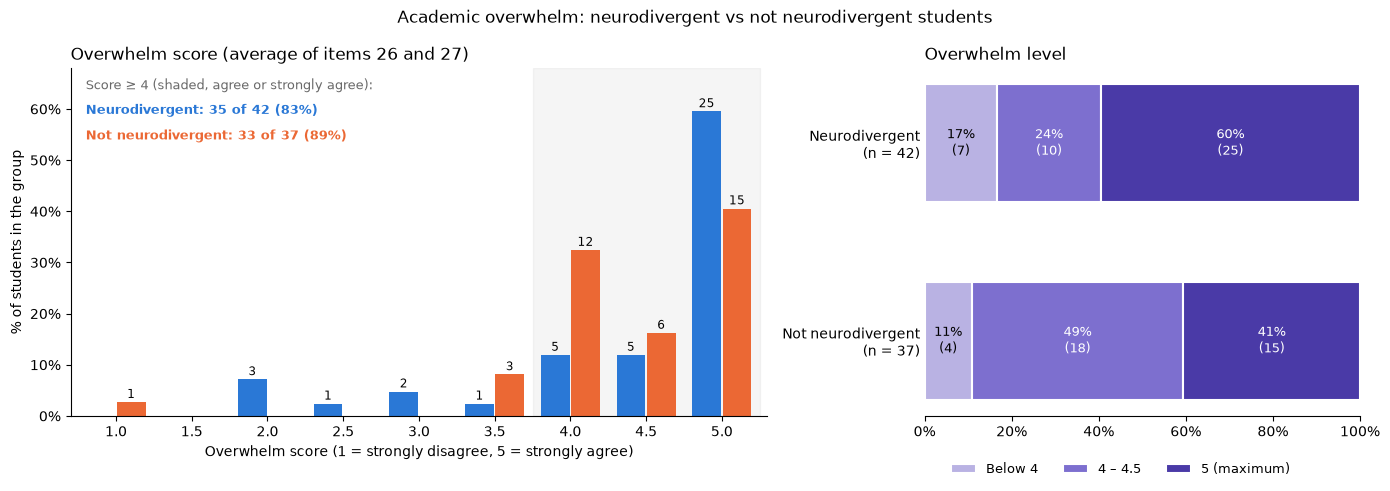

In [5]:
OVERWHELM_COLS = ["26", "27"]  # overwhelmed by academic expectations / by academic workload, each 1-5

# Overwhelm score = average of the two answers (4 students skipped item 27, so their score is item 26 alone)
df["overwhelm"] = df[OVERWHELM_COLS].mean(axis=1)
# High overwhelm = overwhelm score of 4 or more (agrees, on average, that they feel overwhelmed)
df["high_overwhelm"] = df["overwhelm"] >= 4
# The three levels from the EDA: below 4, 4 to 4.5, and the maximum score of 5
LEVEL_ORDER = ["Below 4", "4 – 4.5", "5 (maximum)"]
LEVEL_COLORS = ["#b9b2e3", "#7d6fcf", "#4a3aa7"]  # light to dark: more overwhelm
df["overwhelm_level"] = pd.cut(df["overwhelm"], [0, 3.75, 4.75, 5], labels=LEVEL_ORDER)

display(df["27"].isna().groupby(df["nd_group"]).sum().to_frame("skipped item 27"))
display(df.groupby("nd_group")["overwhelm"].agg(
    students="count", average="mean", median="median",
    high_overwhelm=lambda s: (s >= 4).sum(), pct_high=lambda s: (s >= 4).mean() * 100,
    maximum_score=lambda s: (s == 5).sum(), pct_maximum=lambda s: (s == 5).mean() * 100,
).reindex(GROUP_ORDER).round(2))

# Number and % of each group at every possible score, including scores nobody got
levels = [1 + 0.5 * i for i in range(9)]
counts = pd.crosstab(df["overwhelm"], df["nd_group"]).reindex(index=levels, columns=GROUP_ORDER, fill_value=0)
shares = counts / counts.sum()
level_counts = pd.crosstab(df["overwhelm_level"], df["nd_group"]).reindex(index=LEVEL_ORDER, columns=GROUP_ORDER)
level_shares = level_counts / level_counts.sum()
display(pd.concat({"students": counts, "% of group": (shares * 100).round(0)}, axis=1))
display(pd.concat({"students": level_counts, "% of group": (level_shares * 100).round(0)}, axis=1))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1.6, 1]})

# Left: % of each group at each overwhelm score
ax1.axvspan(3.75, 5.25, color="grey", alpha=0.08)
ax1.text(0.8, 0.66, "Score ≥ 4 (shaded, agree or strongly agree):", fontsize=9, color="dimgrey", va="top")
for k, (group, color) in enumerate(zip(GROUP_ORDER, GROUP_COLORS)):
    offset = (k - 0.5) * 0.2
    bars = ax1.bar([lv + offset for lv in levels], shares[group], width=0.19, color=color)
    for bar, n in zip(bars, counts[group]):
        if n > 0:
            ax1.annotate(str(n), (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                         xytext=(0, 3), textcoords="offset points", ha="center", fontsize=8.5)
    # The colored labels double as the legend
    high, n = counts.loc[[4.0, 4.5, 5.0], group].sum(), counts[group].sum()
    ax1.text(0.8, 0.61 - 0.05 * k, f"{group}: {high} of {n} ({high / n:.0%})",
             fontsize=9.5, color=color, fontweight="bold", va="top")
ax1.set_xticks(levels)
ax1.set_xlim(0.7, 5.3)
ax1.set_ylim(0, 0.68)
ax1.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=0))
ax1.set_xlabel("Overwhelm score (1 = strongly disagree, 5 = strongly agree)")
ax1.set_ylabel("% of students in the group")
ax1.set_title("Overwhelm score (average of items 26 and 27)", loc="left")
ax1.spines[["top", "right"]].set_visible(False)

# Right: the three overwhelm levels as 100% stacked bars
for i, group in enumerate(GROUP_ORDER):
    left = 0
    for level, color in zip(LEVEL_ORDER, LEVEL_COLORS):
        w, n = level_shares.loc[level, group], level_counts.loc[level, group]
        ax2.barh(i, w, left=left, height=0.6, color=color, edgecolor="white", linewidth=1.5,
                 label=level if i == 0 else None)
        ax2.text(left + w / 2, i, f"{w:.0%}\n({n})", ha="center", va="center", fontsize=9,
                 color="white" if level != "Below 4" else "black")
        left += w
ax2.set_yticks(range(len(GROUP_ORDER)), [f"{g}\n(n = {counts[g].sum()})" for g in GROUP_ORDER])
ax2.invert_yaxis()
ax2.set_xlim(0, 1)
ax2.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=0))
ax2.set_title("Overwhelm level", loc="left")
ax2.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.45, -0.1), frameon=False, fontsize=9)
ax2.spines[["top", "right", "left"]].set_visible(False)
ax2.tick_params(axis="y", length=0)

fig.suptitle("Academic overwhelm: neurodivergent vs not neurodivergent students")
plt.tight_layout()
plt.show()

### Average answers by overwhelm group

**Columns used**
- The **high overwhelm** (score of 4 or more) and **low/moderate overwhelm** (below 4) groups, from the previous chart.
- Four questions answered from 1 to 5:
  - **Feeling anxious or overwhelmed (63)**, **Feeling depressed (64)**, **Stress level (48)**: a higher number means more often or more intense.
  - **Mental state since starting uni (51)**: 1 = greatly worsened, 3 = no change, 5 = greatly improved. A **lower** number means the student's mental state has **got worse** since starting vet school.
- Neurodivergent vs not neurodivergent (column 9, as in the first chart).

**What the graph shows**
- The EDA chart drawn twice: **left** for neurodivergent students, **right** for not neurodivergent students. In each, the **average answer** of the low/moderate overwhelm group (green) and the high overwhelm group (purple).
- The number of students in each overwhelm group is in the legend. The table above the chart gives the averages and differences for every question.

**Conclusions**
- **In both groups, highly overwhelmed students are worse off** on feeling depressed (ND 2.9 → 3.4, not ND 2.2 → 3.1), stress (3.6 → 4.4 and 4.0 → 4.3) and mental state since starting university (2.9 → 1.9 and 2.8 → 2.1, from close to *no change* to *worsened*). The link between overwhelm and distress found in the EDA holds for ND and not ND students alike.
- **Highly overwhelmed ND and not ND students answer almost the same**: anxious or overwhelmed 4.2 vs 4.2, depressed 3.4 vs 3.1, stress 4.4 vs 4.3, mental state 1.9 vs 2.1.
- **Feeling anxious or overwhelmed (63)** rises clearly with overwhelm among ND students (3.1 → 4.2), but barely among not ND students (4.0 → 4.2). The not ND low/moderate group is only 4 students, so this difference between the groups cannot be relied on.

**Limits**
- **The low/moderate overwhelm groups are very small: 7 ND and 4 not ND students.** In a group of 4, one student moves the average by up to a full point, so the green bars are only rough indications, especially on the right.
- Question 63 contains the word *overwhelmed*, so part of its link with the overwhelm score is because they ask about the same feeling.
- Column 51 is the student's own memory of how they felt before university, not a measurement taken at the time.
- A link, not proof of cause: students who were already anxious or depressed may experience the same workload as more overwhelming.

,group,question,n low/moderate,n high,low/moderate overwhelm average,high overwhelm average,difference
0,Neurodivergent,Feeling anxious or overwhelmed (63),7,35,3.143,4.171,1.029
1,Neurodivergent,Feeling depressed (64),7,35,2.857,3.429,0.571
2,Neurodivergent,Stress level (48),7,35,3.571,4.371,0.800
3,Neurodivergent,Mental state since uni (51) 1 = greatly worse ...,7,35,2.857,1.914,-0.943
4,Not neurodivergent,Feeling anxious or overwhelmed (63),4,33,4.000,4.242,0.242
5,Not neurodivergent,Feeling depressed (64),4,33,2.250,3.091,0.841
6,Not neurodivergent,Stress level (48),4,33,4.000,4.273,0.273
7,Not neurodivergent,Mental state since uni (51) 1 = greatly worse ...,4,33,2.750,2.121,-0.629


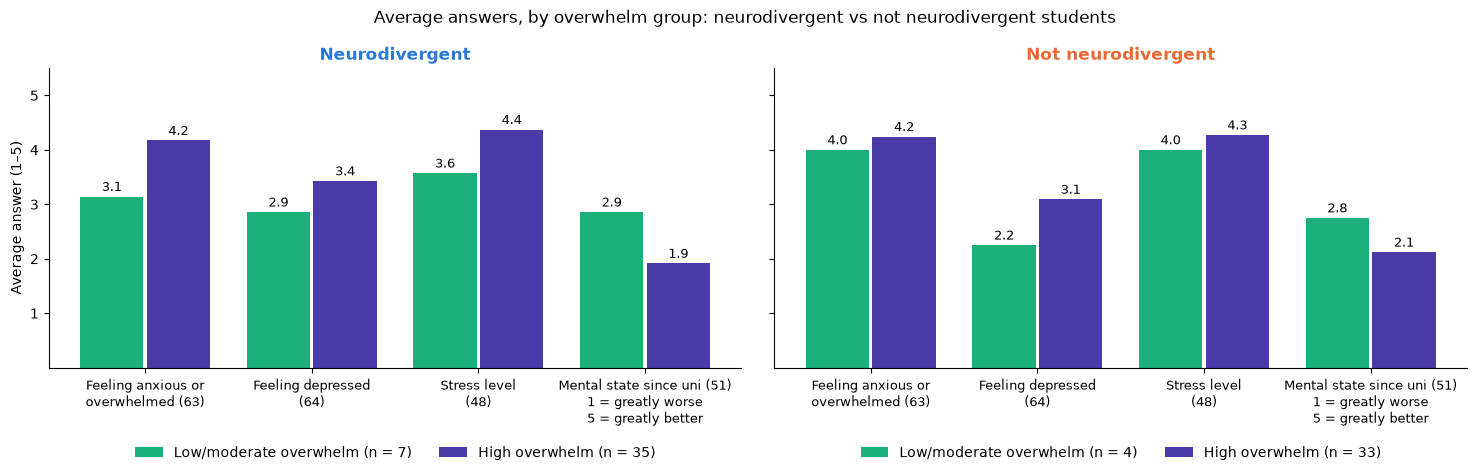

In [6]:
HIGH_COLOR = "#4a3aa7"
LOW_COLOR = "#1baf7a"
OVERWHELM_GROUPS = [("Low/moderate overwhelm", False, LOW_COLOR), ("High overwhelm", True, HIGH_COLOR)]

QUESTIONS = [
    ("Feeling anxious or\noverwhelmed (63)", "63"),
    ("Feeling depressed\n(64)", "64"),
    ("Stress level\n(48)", "48"),
    ("Mental state since uni (51)\n1 = greatly worse\n5 = greatly better", "51"),
]

# The EDA table, once per ND group
rows = []
for group in GROUP_ORDER:
    in_group = df["nd_group"] == group
    for name, col in QUESTIONS:
        low = df.loc[in_group & ~df["high_overwhelm"], col].dropna()
        high = df.loc[in_group & df["high_overwhelm"], col].dropna()
        rows.append({
            "group": group,
            "question": name.replace("\n", " "),
            "n low/moderate": len(low),
            "n high": len(high),
            "low/moderate overwhelm average": low.mean(),
            "high overwhelm average": high.mean(),
            "difference": high.mean() - low.mean(),
        })
averages = pd.DataFrame(rows)
display(averages.round(3))

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
x = range(len(QUESTIONS))
for ax, group, title_color in zip(axes, GROUP_ORDER, GROUP_COLORS):
    part = averages[averages["group"] == group]
    for offset, (label, is_high, color) in zip([-0.2, 0.2], OVERWHELM_GROUPS):
        col = "high overwhelm average" if is_high else "low/moderate overwhelm average"
        n = ((df["nd_group"] == group) & (df["high_overwhelm"] == is_high)).sum()
        bars = ax.bar([i + offset for i in x], part[col], width=0.38, color=color, label=f"{label} (n = {n})")
        for bar, value in zip(bars, part[col]):
            ax.annotate(f"{value:.1f}", (bar.get_x() + bar.get_width() / 2, value),
                        xytext=(0, 4), textcoords="offset points", ha="center", fontsize=9)
    ax.set_xticks(list(x), [name for name, _ in QUESTIONS], fontsize=9)
    ax.set_ylim(0, 5.5)
    ax.set_yticks([1, 2, 3, 4, 5])
    ax.set_title(group, color=title_color, fontweight="bold")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2, frameon=False)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Average answer (1–5)")
fig.suptitle("Average answers, by overwhelm group: neurodivergent vs not neurodivergent students")
plt.tight_layout()
plt.show()

### Daily wellbeing and lifestyle by overwhelm group

**Columns used**
- Columns 41–47: seven lifestyle statements, answered from 1 (strongly disagree) to 5 (strongly agree).
- Column 48: overall stress level, from 1 to 5.
- Neurodivergent vs not neurodivergent (column 9), and **high overwhelm** (score of 4 or more) vs **low/moderate overwhelm** (below 4), from the overwhelm score chart.
- Every student answered all eight questions.

**What the graph shows**
- The EDA's lifestyle heatmap, with the year-of-study columns replaced by groups of students. Each box is the **% of students in that group who agree** (answered 4 or 5). Darker blue = more students agree.
- **Left block:** all neurodivergent vs all not neurodivergent students.
- **Right block:** each ND group split by overwhelm: low/moderate, then high. The low/moderate columns (7 and 4 students) are labelled *very small*.
- The last row, **stress (48)**, shows the % of students with **high or very high stress** (4 or 5). It is set apart because here a *higher* % means *worse* wellbeing.

**Conclusions**
- **Neurodivergent students agree less often with almost every lifestyle statement.** The biggest gaps are sleeping 7–9 hours (29% vs 46%) and socialising regularly (31% vs 49%), followed by speaking with family often (67% vs 81%), time for errands (21% vs 30%) and regular meals (43% vs 51%). Exercise is the same (38% in both). Each gap alone could be chance, but 6 of the 7 statements point the same way.
- **Stress is just as high in both groups** (81% vs 86% high or very high), so the lifestyle gap is not explained by ND students being more stressed.
- **Overwhelm goes with stress**: among ND students, 86% of the highly overwhelmed have high stress, against 57% (4 of 7) of the low/moderate group. Among not ND students it is 88% vs 75% (3 of 4).
- **Overwhelm does not go with worse lifestyle habits.** Highly overwhelmed students sleep, eat and socialise about as often as the less overwhelmed ones in their group (e.g. ND sleep 29% vs 29%, meals 43% vs 43%). What separates the groups more is being ND or not, not how overwhelmed the student is.

**Limits**
- The low/moderate overwhelm groups are **7 ND and 4 not ND students**: one student is 14% or 25% of the group, so those columns cannot be compared reliably. The 0% for exercise and errands among the 4 not ND students, for example, is just 4 students who disagreed.
- With about 40 students per ND group, one student is about 2.5%: a 10-point gap is about 4 students.

,ND all (n = 42),Not ND all (n = 37),ND low/moderate overwhelm (n = 7),ND high overwhelm (n = 35),Not ND low/moderate overwhelm (n = 4),Not ND high overwhelm (n = 33)
Eat regular meals (41),43.0,51.0,43.0,43.0,50.0,52.0
Sleep 7–9 hours (42),29.0,46.0,29.0,29.0,50.0,45.0
Socialize regularly (43),31.0,49.0,29.0,31.0,75.0,45.0
Exercise 2–3 times a week (44),38.0,38.0,43.0,37.0,0.0,42.0
Time for errands (45),21.0,30.0,14.0,23.0,0.0,33.0
Contact with people back home (46),40.0,46.0,14.0,46.0,25.0,48.0
Speak with family often (47),67.0,81.0,86.0,63.0,75.0,82.0
High stress (48) – higher % is worse,81.0,86.0,57.0,86.0,75.0,88.0


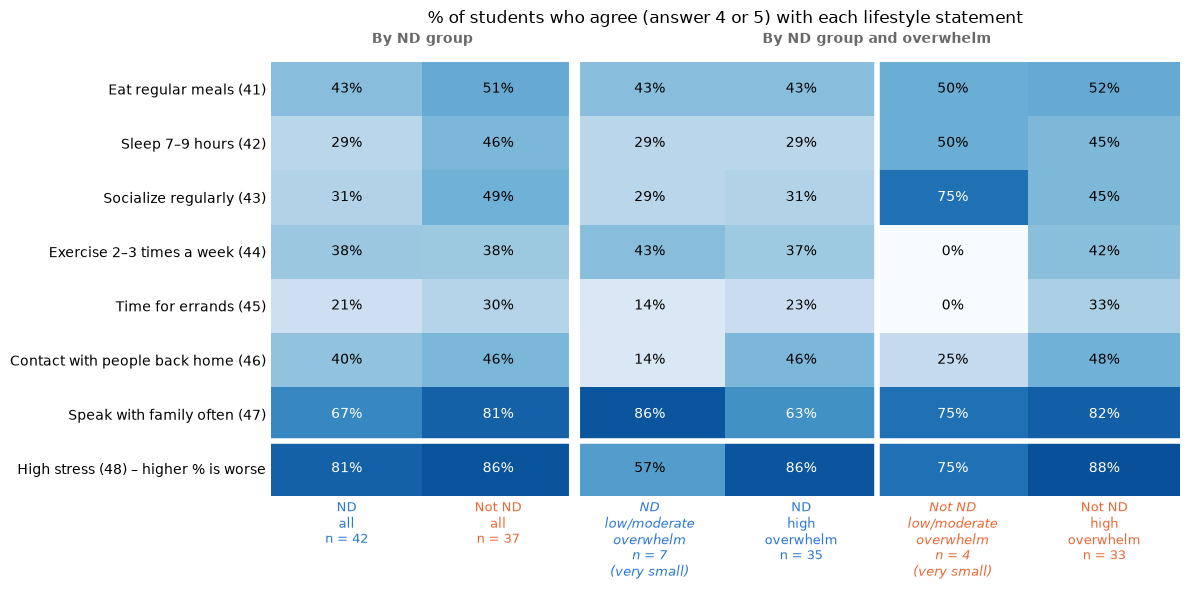

In [7]:
LIFESTYLE = [
    ("41", "Eat regular meals (41)"),
    ("42", "Sleep 7–9 hours (42)"),
    ("43", "Socialize regularly (43)"),
    ("44", "Exercise 2–3 times a week (44)"),
    ("45", "Time for errands (45)"),
    ("46", "Contact with people back home (46)"),
    ("47", "Speak with family often (47)"),
    ("48", "Stress level (48)"),
]
LIFESTYLE_COLS = [col for col, _ in LIFESTYLE]
# In this chart the stress row counts students with HIGH stress, so a higher % means worse wellbeing
AGREE_LABELS = [label for _, label in LIFESTYLE][:-1] + ["High stress (48) – higher % is worse"]
SHORT = {"Neurodivergent": "ND", "Not neurodivergent": "Not ND"}

# Columns: each ND group, then each ND group split into low/moderate and high overwhelm
groups = [(f"{SHORT[g]}\nall", df["nd_group"] == g) for g in GROUP_ORDER]
for g in GROUP_ORDER:
    for label, is_high in [("low/moderate\noverwhelm", False), ("high\noverwhelm", True)]:
        groups.append((f"{SHORT[g]}\n{label}", (df["nd_group"] == g) & (df["high_overwhelm"] == is_high)))

# % of each group answering 4 or 5 (agree / strongly agree; for stress: high / very high)
agree_answers = (df[LIFESTYLE_COLS] >= 4).where(df[LIFESTYLE_COLS].notna())
agree = pd.DataFrame({name: agree_answers[mask].mean() for name, mask in groups}).set_axis(AGREE_LABELS)
ns = {name: mask.sum() for name, mask in groups}
display((agree * 100).round(0).set_axis([f"{name.replace(chr(10), ' ')} (n = {ns[name]})" for name in agree.columns], axis=1))

fig, ax = plt.subplots(figsize=(12, 6))
im = ax.imshow(agree.values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
for r in range(agree.shape[0]):
    for c in range(agree.shape[1]):
        value = agree.iat[r, c]
        ax.text(c, r, f"{value:.0%}", ha="center", va="center", fontsize=10, color="white" if value > 0.6 else "black")
ax.axhline(6.5, color="white", linewidth=4)  # stress is set apart: for it, a high % means worse wellbeing
ax.axvline(1.5, color="white", linewidth=8)  # all students | split by overwhelm
ax.axvline(3.5, color="white", linewidth=4)  # ND | not ND within the overwhelm block
for x, header in [(0.5, "By ND group"), (3.5, "By ND group and overwhelm")]:
    ax.text(x, -0.85, header, ha="center", fontsize=10, fontweight="bold", color="dimgrey")
# The low/moderate overwhelm columns are very small (7 and 4 students): their labels say so, in italics
ax.set_xticks(range(agree.shape[1]), [f"{name}\nn = {ns[name]}" + ("\n(very small)" if "low" in name else "")
                                      for name in agree.columns], fontsize=9)
for tick, name in zip(ax.get_xticklabels(), agree.columns):
    tick.set_color(ND_COLOR if name.startswith("ND") else NON_ND_COLOR)
    if "low" in name:
        tick.set_style("italic")
ax.set_yticks(range(len(LIFESTYLE)), AGREE_LABELS)
ax.tick_params(length=0)
ax.spines[:].set_visible(False)
ax.set_title("% of students who agree (answer 4 or 5) with each lifestyle statement", pad=28)
plt.tight_layout()
plt.show()

## Worsened mental state: ND vs not ND

### Mental state since starting university

**Columns used**
- Column 51, *"Since starting university, my mental state has…"*: 1 = *greatly worsened*, 2 = *worsened*, 3 = *no change*, 4 = *improved*, 5 = *greatly improved*. Every student answered.
- **Worsened** = answered 1 or 2; **not worsened** = answered 3, 4 or 5. *Improved* is merged with *no change* because only 4 students chose it.
- PHQ-9 (depression, 0–27) and GAD-7 (anxiety, 0–21) totals from the screening chart.
- Neurodivergent vs not neurodivergent (column 9, as in the first chart).

**What the graph shows**
- **Left (diverging stacked bars):** how each group answered column 51. *Worsened* answers (red) go **left** of the centre line and *improved* answers (blue) go **right**; *no change* (grey) is split in half across the centre. The further left a bar reaches, the more students say their mental state got worse.
- **Middle and right:** the **average depression and anxiety score** of students whose mental state worsened (red) vs did not (grey), in each group, with the number of students above the bar. The shaded area is a score of 10 or more (at least *moderate* symptoms).

**Conclusions**
- **Most students say their mental state has got worse since starting university, more often ND students**: 74% of ND students (31 of 42) vs 62% of not ND students (23 of 37). 29% of ND students say it *greatly* worsened, against 22%.
- **Not ND students more often report no change** (35% vs 19%, 13 vs 8 students). Almost nobody in either group says it improved (3 ND and 1 not ND student).
- **In both groups, students whose mental state worsened have more depression symptoms** (ND 16.0 vs 13.9, not ND 15.1 vs 11.9).
- **For anxiety, the groups differ.** ND students whose mental state worsened have much more anxiety than those whose state did not (13.4 vs 8.9; 84% vs 45% score 10 or more). Among not ND students there is no such gap (12.1 vs 12.6): those whose state did not worsen are just as anxious. For ND students, a worse mental state at university seems to go together with anxiety; for not ND students, the anxiety seems to be there either way.

**Limits**
- The *not worsened* groups are small (11 ND and 14 not ND students), so their averages could shift with a few more answers. The anxiety difference between ND and not ND students rests on these small groups and is a **hint**, not a firm result.
- The 12-point gap in *worsened* (74% vs 62%) is about 5 students and could be chance.
- Column 51 is the student's own memory of how they felt before university, not a measurement taken at the time, and graduates answer about a period that has already ended.
- A link, not proof of cause: a worse mental state and higher scores describe the same students at one moment in time.

students                        % of group  \
nd_group             Neurodivergent Not neurodivergent Neurodivergent   
1 – Greatly worsened             12                  8           29.0   
2 – Worsened                     19                 15           45.0   
3 – No change                     8                 13           19.0   
4 – Improved                      2                  1            5.0   
5 – Greatly improved              1                  0            2.0   

                                         
nd_group             Not neurodivergent  
1 – Greatly worsened               22.0  
2 – Worsened                       41.0  
3 – No change                      35.0  
4 – Improved                        3.0  
5 – Greatly improved                0.0

,students,average,worsened,pct_worsened
nd_group,,,,
Neurodivergent,42,2.07,31,73.81
Not neurodivergent,37,2.19,23,62.16


Depression (PHQ-9) n  \
group              mental state                               
Neurodivergent     Not worsened (3–5)                    11   
                   Worsened (1–2)                        31   
Not neurodivergent Not worsened (3–5)                    14   
                   Worsened (1–2)                        21   

                                       Depression (PHQ-9) average  \
group              mental state                                     
Neurodivergent     Not worsened (3–5)                        13.9   
                   Worsened (1–2)                            16.0   
Not neurodivergent Not worsened (3–5)                        11.9   
                   Worsened (1–2)                            15.1   

                                       Depression (PHQ-9) % ≥ 10  \
group              mental state                                    
Neurodivergent     Not worsened (3–5)                       72.7   
                   Worsened (1–2)                           80.6   
Not neurodivergent Not worsened (3–5)                       64.3   
                   Worsened (1–2)                           81.0   

                                       Anxiety (GAD-7) n  \
group              mental state                            
Neurodivergent     Not worsened (3–5)                 11   
                   Worsened (1–2)                     31   
Not neurodivergent Not worsened (3–5)                 14   
                   Worsened (1–2)                     23   

                                       Anxiety (GAD-7) average  \
group              mental state                                  
Neurodivergent     Not worsened (3–5)                      8.9   
                   Worsened (1–2)                         13.4   
Not neurodivergent Not worsened (3–5)                     12.6   
                   Worsened (1–2)                         12.1   

                                       Anxiety (GAD-7) % ≥ 10  
group              mental state                                
Neurodivergent     Not worsened (3–5)                    45.5  
                   Worsened (1–2)                        83.9  
Not neurodivergent Not worsened (3–5)                    78.6  
                   Worsened (1–2)                        69.6

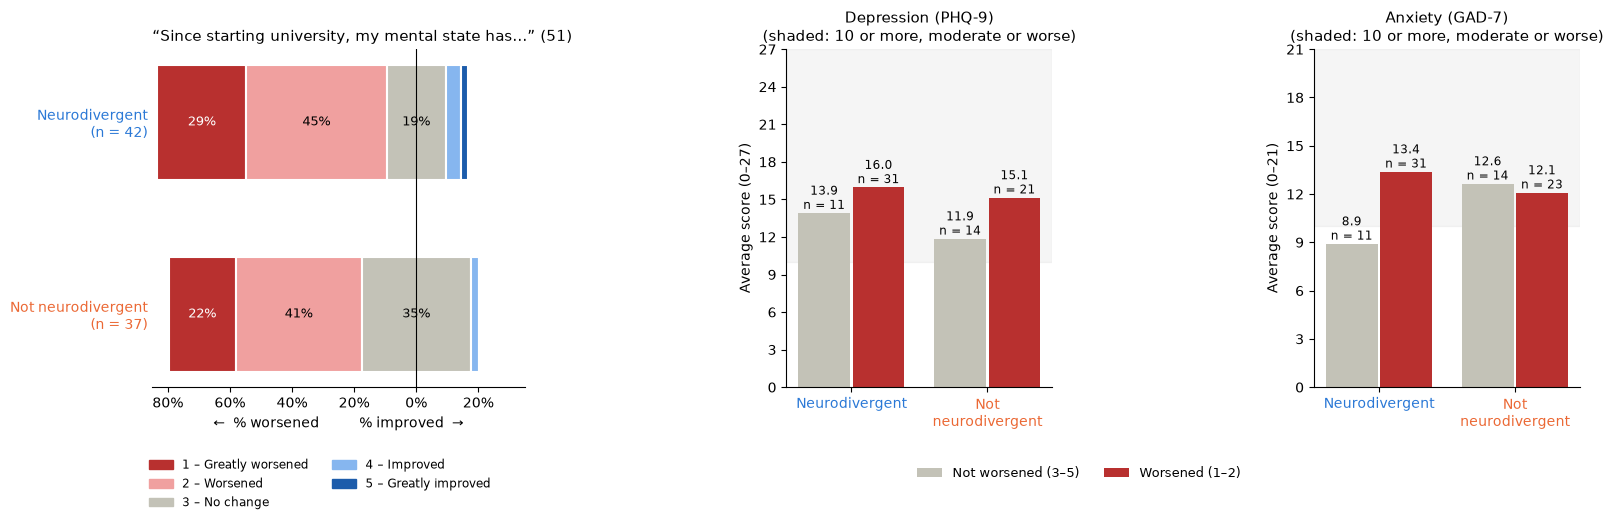

In [8]:
MENTAL_STATE_LABELS = ["1 – Greatly worsened", "2 – Worsened", "3 – No change", "4 – Improved", "5 – Greatly improved"]
MENTAL_STATE_COLORS = ["#b8302f", "#f0a09f", "#c3c2b7", "#86b6ef", "#1c5cab"]  # same red → grey → blue scale as the EDA
WORSE_COLOR, NOT_WORSE_COLOR = "#b8302f", "#c3c2b7"

# Column 51: 1 = greatly worsened, 3 = no change, 5 = greatly improved. Worsened = answered 1 or 2
df["worsened"] = df["51"] <= 2
counts_51 = pd.crosstab(df["51"], df["nd_group"]).reindex(index=range(1, 6), columns=GROUP_ORDER, fill_value=0)
shares_51 = counts_51 / counts_51.sum()
display(pd.concat({"students": counts_51, "% of group": (shares_51 * 100).round(0)}, axis=1)
        .set_axis(MENTAL_STATE_LABELS))
display(df.groupby("nd_group")["51"].agg(
    students="count", average="mean", worsened=lambda s: (s <= 2).sum(), pct_worsened=lambda s: (s <= 2).mean() * 100,
).reindex(GROUP_ORDER).round(2))

# Depression and anxiety scores of students whose mental state worsened (1–2) vs did not (3–5), in each ND group
DISTRESS = [("Depression (PHQ-9)", "phq9_total", 27), ("Anxiety (GAD-7)", "gad7_total", 21)]
rows = []
for group in GROUP_ORDER:
    for worsened in [False, True]:
        part = df[(df["nd_group"] == group) & (df["worsened"] == worsened)]
        row = {"group": group, "mental state": "Worsened (1–2)" if worsened else "Not worsened (3–5)"}
        for name, col, _ in DISTRESS:
            scores = part[col].dropna()
            row |= {f"{name} n": len(scores), f"{name} average": scores.mean(), f"{name} % ≥ 10": (scores >= 10).mean() * 100}
        rows.append(row)
by_state = pd.DataFrame(rows).set_index(["group", "mental state"])
display(by_state.round(1))

fig, axes = plt.subplots(1, 3, figsize=(16, 5.5), gridspec_kw={"width_ratios": [1.4, 1, 1]})

# Left: diverging stacked bars, worsened to the left of the centre line and improved to the right
ax = axes[0]
for i, group in enumerate(GROUP_ORDER):
    shares = shares_51[group].values
    left = -(shares[0] + shares[1] + shares[2] / 2)  # centre the bar on the middle of "no change"
    for share, color in zip(shares, MENTAL_STATE_COLORS):
        ax.barh(i, share, left=left, height=0.6, color=color, edgecolor="white", linewidth=1.5)
        if share >= 0.07:
            ax.text(left + share / 2, i, f"{share:.0%}", ha="center", va="center", fontsize=9,
                    color="white" if color in ("#b8302f", "#1c5cab") else "black")
        left += share
ax.axvline(0, color="black", linewidth=0.8)
ax.set_yticks(range(len(GROUP_ORDER)), [f"{g}\n(n = {counts_51[g].sum()})" for g in GROUP_ORDER])
for tick, color in zip(ax.get_yticklabels(), GROUP_COLORS):
    tick.set_color(color)
ax.invert_yaxis()
ax.set_xlim(-0.85, 0.35)
ax.set_xticks([-0.8, -0.6, -0.4, -0.2, 0, 0.2])
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{abs(x):.0%}"))
ax.set_xlabel("←  % worsened          % improved  →")
ax.set_title("“Since starting university, my mental state has…” (51)", loc="left", fontsize=11)
ax.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in MENTAL_STATE_COLORS], MENTAL_STATE_LABELS,
          ncol=2, loc="upper center", bbox_to_anchor=(0.45, -0.18), frameon=False, fontsize=8.5)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0)

# Middle and right: average depression / anxiety score, worsened vs not worsened, in each ND group
for ax, (name, col, max_score) in zip(axes[1:], DISTRESS):
    ax.axhspan(10, max_score, color="grey", alpha=0.08)
    for i, group in enumerate(GROUP_ORDER):
        for offset, worsened, color in [(-0.2, False, NOT_WORSE_COLOR), (0.2, True, WORSE_COLOR)]:
            scores = df.loc[(df["nd_group"] == group) & (df["worsened"] == worsened), col].dropna()
            ax.bar(i + offset, scores.mean(), width=0.38, color=color,
                   label=("Worsened (1–2)" if worsened else "Not worsened (3–5)") if i == 0 else None)
            ax.annotate(f"{scores.mean():.1f}\nn = {len(scores)}", (i + offset, scores.mean()),
                        xytext=(0, 3), textcoords="offset points", ha="center", fontsize=8.5)
    ax.set_xticks(range(len(GROUP_ORDER)), ["Neurodivergent", "Not\nneurodivergent"])
    for tick, color in zip(ax.get_xticklabels(), GROUP_COLORS):
        tick.set_color(color)
    ax.set_ylim(0, max_score)
    ax.set_yticks(range(0, max_score + 1, 3))
    ax.set_ylabel(f"Average score (0–{max_score})")
    ax.set_title(f"{name}\n(shaded: 10 or more, moderate or worse)", fontsize=11)
    ax.spines[["top", "right"]].set_visible(False)
axes[1].legend(loc="upper center", bbox_to_anchor=(1.1, -0.2), ncol=2, frameon=False, fontsize=9)

plt.tight_layout()
plt.show()

## Perceived social support: ND vs not ND

### Social support by source (MSPSS)

**Columns used**
- Columns **86–97**, the 12 items of the **MSPSS** (*Multidimensional Scale of Perceived Social Support*), each answered from 1 (*very strongly disagree*) to 7 (*very strongly agree*), in three sources of 4 items: **partner (86–89)**, **family (90–93)** and **friends (94–97)**.
- **No partner = N/A**, as in the EDA: students who answered 1 on all four partner items are treated as having no partner, not as having a partner who gives no support. This applies to 15 ND students (36%) and 11 not ND students (30%).
- **Scores**: each source is the average of its 4 items (official scoring). **Overall** is the average of every item that applies to the student, so students without a partner are scored on family and friends only.
- **Levels**: the standard MSPSS bands, **low** (1–2.9), **moderate** (3–5) and **high** (5.1–7).
- Neurodivergent vs not neurodivergent (column 9, as in the first chart).

**What the graph shows**
- **Left (100% stacked bars):** for each source, the % of each group with low (red), moderate (grey) and high (blue) support.
- **Right (dumbbell chart):** for each item, the % of students who **agree** (5–7): blue = neurodivergent, orange = not neurodivergent. The grey line shows the gap, and the number on the right is ND minus not ND in percentage points. Partner items only count students with a partner.
- The EDA showed the same scores as box plots; this chart looks at the levels and at every single item.

**Conclusions**
- **Neurodivergent students feel a little less supported, and this is consistent across the scale.** They agree less often with **11 of the 12 items** (the 12th is equal). Overall, 52% of ND students have high support against 62% of not ND students (average 5.1 vs 5.4), and the only 3 students with low overall support are all ND.
- **The biggest gaps are for the partner**: among students with a partner, fewer ND students say their partner is *a real source of comfort* (67% vs 88%) or *is around when I am in need* (70% vs 85%).
- **Family is the weakest source in both groups**, as in the EDA: only about half get the emotional help they need (48% vs 51%) or can talk to their family about their problems (48% vs 54%). The largest family gap is *helps me make decisions* (57% vs 70%).
- **Friends give similar support to both groups** (gaps of 2–7 points), and ND students more often have high support from friends than from family (52% vs 40%).
- ND students also more often have **no partner** (36% vs 30%).

**Limits**
- Each single gap is small: with about 40 students per group, 10 points is about 4 students, and among students with a partner (27 and 26) the 22-point gap is about 6 students. No single item is a firm result; what is more convincing is that **almost every item points the same way**.
- The EDA concluded that ND and not ND students *feel similar levels of support*. The two readings fit together: the difference is small and consistent, not large.
- The "no partner" rule is an assumption, as explained in the EDA.

,students,no_partner,pct_no_partner
nd_group,,,
Neurodivergent,42,15,36.0
Not neurodivergent,37,11,30.0


nd_group Neurodivergent              Not neurodivergent             
                  count  mean median              count  mean median
Overall            42.0  5.05   5.10               37.0  5.41   5.42
Partner            27.0  5.61   6.50               26.0  5.93   6.12
Family             42.0  4.56   4.50               37.0  4.86   5.00
Friends            42.0  5.32   5.25               37.0  5.56   6.00

nd_group                Neurodivergent  Not neurodivergent
source  level                                             
Overall Low (1–2.9)                  3                   0
        Moderate (3–5)              17                  14
        High (5.1–7)                22                  23
Partner Low (1–2.9)                  2                   0
        Moderate (3–5)               9                   8
        High (5.1–7)                16                  18
Family  Low (1–2.9)                  7                   5
        Moderate (3–5)              18                  14
        High (5.1–7)                17                  18
Friends Low (1–2.9)                  4                   1
        Moderate (3–5)              16                  12
        High (5.1–7)                22                  24

nd_group,Neurodivergent,Not neurodivergent
86,70.37037,84.615385
87,66.666667,80.769231
88,66.666667,88.461538
89,77.777778,88.461538
90,59.52381,59.459459
91,47.619048,51.351351
92,47.619048,54.054054
93,57.142857,70.27027
94,69.047619,75.675676
95,69.047619,75.675676


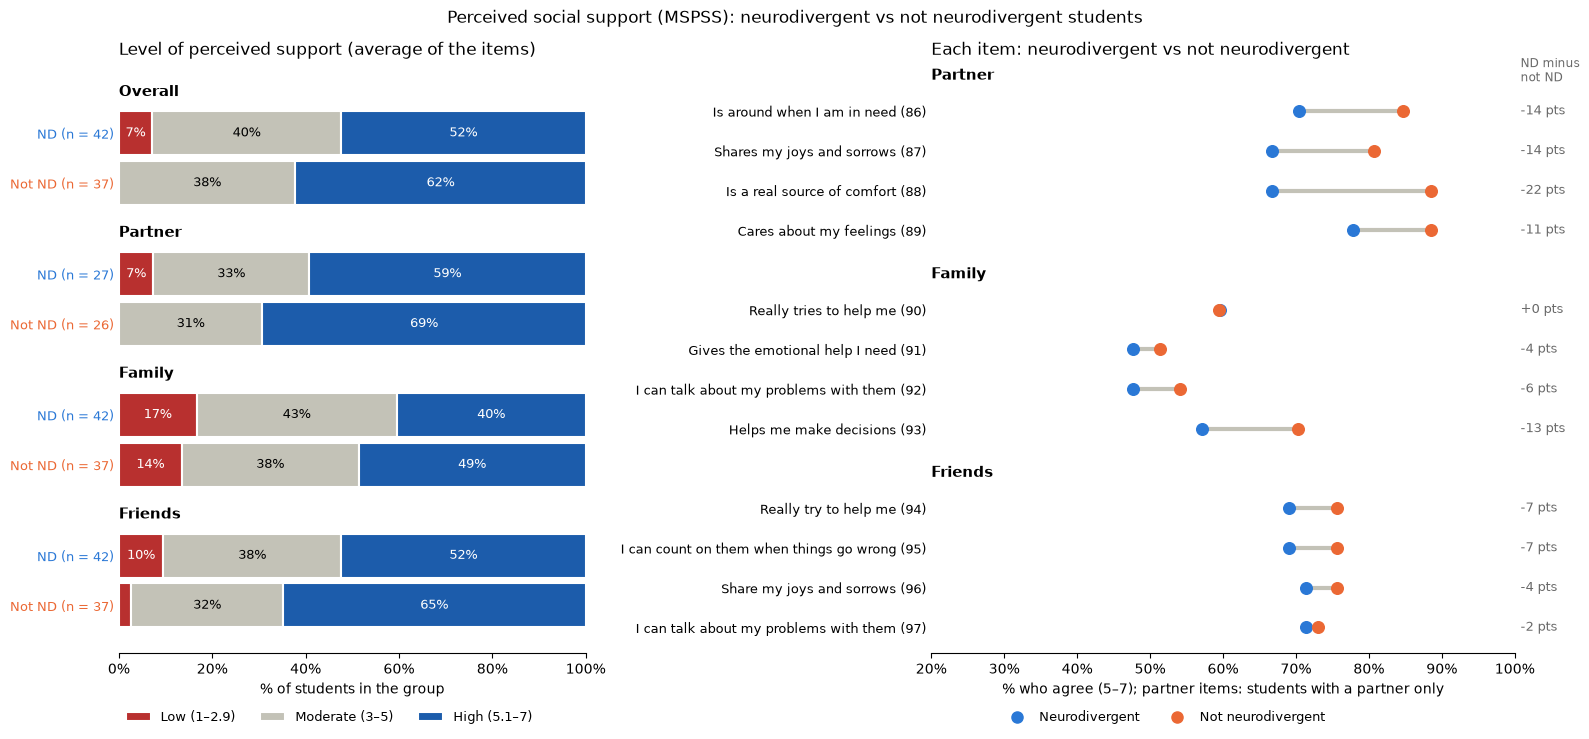

In [9]:
import numpy as np

# MSPSS (Multidimensional Scale of Perceived Social Support): 12 items, 1-7, in three sources of 4 items
MSPSS = {
    "Partner": [("86", "Is around when I am in need"),
                ("87", "Shares my joys and sorrows"),
                ("88", "Is a real source of comfort"),
                ("89", "Cares about my feelings")],
    "Family":  [("90", "Really tries to help me"),
                ("91", "Gives the emotional help I need"),
                ("92", "I can talk about my problems with them"),
                ("93", "Helps me make decisions")],
    "Friends": [("94", "Really try to help me"),
                ("95", "I can count on them when things go wrong"),
                ("96", "Share my joys and sorrows"),
                ("97", "I can talk about my problems with them")],
}
PARTNER_COLS = [col for col, _ in MSPSS["Partner"]]
MSPSS_COLS = [col for items in MSPSS.values() for col, _ in items]
values = df[MSPSS_COLS].stack().dropna()
assert values.between(1, 7).all() and (values % 1 == 0).all(), "MSPSS answers outside 1-7"

# Students who answered 1 on all four partner items almost certainly have no partner: they are N/A, not "no support"
df["no_partner"] = (df[PARTNER_COLS] == 1).all(axis=1)
mspss = df[MSPSS_COLS].astype(float)
mspss.loc[df["no_partner"], PARTNER_COLS] = np.nan
display(df.groupby("nd_group")["no_partner"].agg(students="count", no_partner="sum",
                                                 pct_no_partner=lambda s: s.mean() * 100).reindex(GROUP_ORDER).round(0))

# Source score = average of its 4 items (official MSPSS scoring); overall = average of every item that applies
SOURCES = ["Overall", *MSPSS]
scores = pd.DataFrame({"Overall": mspss.mean(axis=1),
                       **{source: mspss[[col for col, _ in items]].mean(axis=1) for source, items in MSPSS.items()}})
display(scores.groupby(df["nd_group"]).agg(["count", "mean", "median"]).T.unstack().reindex(columns=GROUP_ORDER, level=0).round(2))

# Standard MSPSS levels: low 1–2.9, moderate 3–5, high 5.1–7
LEVELS = ["Low (1–2.9)", "Moderate (3–5)", "High (5.1–7)"]
LEVEL_COLORS = ["#b8302f", "#c3c2b7", "#1c5cab"]  # same red / grey / blue as the EDA
levels = scores.apply(lambda s: pd.cut(s, [0, 2.99, 5.0, 7], labels=LEVELS))
level_counts = {source: pd.crosstab(levels[source], df["nd_group"]).reindex(index=LEVELS, columns=GROUP_ORDER, fill_value=0)
                for source in SOURCES}
display(pd.concat(level_counts).rename_axis(["source", "level"]))

# % of each group who agree (5–7) with each item; partner items only among students with a partner
agree_items = (mspss >= 5).where(mspss.notna()).groupby(df["nd_group"]).mean().T.reindex(columns=GROUP_ORDER)
display((agree_items * 100).round(0))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7.5), gridspec_kw={"width_ratios": [1, 1.25]})

# Left: low / moderate / high support, one pair of bars per source
bar_h, pair_gap = 0.75, 2.4
yticks, ylabels = [], []
for i, source in enumerate(SOURCES):
    ax1.text(0, i * pair_gap - 0.7, source, fontsize=11, fontweight="bold", va="center")
    for k, group in enumerate(GROUP_ORDER):
        y = i * pair_gap + k * (bar_h + 0.1)
        counts = level_counts[source][group]
        left = 0
        for level, color in zip(LEVELS, LEVEL_COLORS):
            w = counts[level] / counts.sum()
            ax1.barh(y, w, left=left, height=bar_h, color=color, edgecolor="white", linewidth=1.5,
                     label=level if (i, k) == (0, 0) else None)
            if w >= 0.07:
                ax1.text(left + w / 2, y, f"{w:.0%}", ha="center", va="center", fontsize=9,
                         color="black" if level.startswith("Moderate") else "white")
            left += w
        yticks.append(y)
        ylabels.append(f"{SHORT[group]} (n = {counts.sum()})")
ax1.set_yticks(yticks, ylabels, fontsize=9)
for tick, label in zip(ax1.get_yticklabels(), ylabels):
    tick.set_color(ND_COLOR if label.startswith("ND") else NON_ND_COLOR)
ax1.invert_yaxis()
ax1.set_xlim(0, 1)
ax1.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=0))
ax1.set_xlabel("% of students in the group")
ax1.set_title("Level of perceived support (average of the items)", loc="left", pad=22)
ax1.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.45, -0.08), frameon=False, fontsize=9)
ax1.spines[["top", "right", "left"]].set_visible(False)
ax1.tick_params(axis="y", length=0)

# Right: % who agree (5–7) with each item, ND vs not ND (dumbbell)
y, yticks, ylabels = 0, [], []
for source, items in MSPSS.items():
    ax2.text(0.2, y - 0.1, source, fontsize=11, fontweight="bold", va="bottom")
    y += 0.6
    for col, text in items:
        nd_v, non_v = agree_items.loc[col, "Neurodivergent"], agree_items.loc[col, "Not neurodivergent"]
        ax2.hlines(y, min(nd_v, non_v), max(nd_v, non_v), color="#c3c2b7", linewidth=3)
        ax2.scatter(nd_v, y, s=70, color=ND_COLOR, zorder=3)
        ax2.scatter(non_v, y, s=70, color=NON_ND_COLOR, zorder=3)
        ax2.text(1.01, y, f"{nd_v - non_v:+.0%}".replace("%", " pts"), transform=ax2.get_yaxis_transform(),
                 va="center", fontsize=9, color="dimgrey")
        yticks.append(y)
        ylabels.append(f"{text} ({col})")
        y += 1
    y += 0.4
ax2.set_yticks(yticks, ylabels, fontsize=9)
ax2.invert_yaxis()
ax2.set_xlim(0.2, 1)
ax2.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=0))
ax2.set_xlabel("% who agree (5–7); partner items: students with a partner only")
ax2.set_title("Each item: neurodivergent vs not neurodivergent", loc="left", pad=22)
ax2.text(1.01, 1.0, "ND minus\nnot ND", transform=ax2.transAxes, fontsize=8.5, color="dimgrey", va="bottom")
ax2.legend([plt.Line2D([], [], marker="o", linestyle="", color=c, markersize=8) for c in GROUP_COLORS], GROUP_ORDER,
           ncol=2, loc="upper center", bbox_to_anchor=(0.4, -0.08), frameon=False, fontsize=9)
ax2.spines[["top", "right", "left"]].set_visible(False)
ax2.tick_params(axis="y", length=0)

fig.suptitle("Perceived social support (MSPSS): neurodivergent vs not neurodivergent students")
plt.tight_layout()
plt.show()